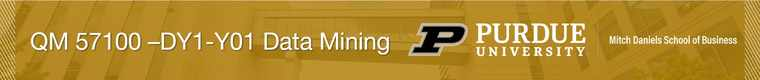

# QM 57100 — Data Mining | Module 3, Week 5 Lab
## **Decision Trees (CART):** grow a tree, choose its size with cross-validation, read its rules and use it

| | |
|---|---|
| **Format** | Google Colab notebook (Python) |
| **Companion to** | Lesson 5 video: Decision Trees |
| **Datasets** | **Creditcard_appr.csv** — 689 credit-card applications reviewed by U.S. Bank's retail credit team: the decision (target) and ten applicant characteristics.<br> **Creditcard_appr_newclts.csv** — 20 new applicants used in Section 7 |
| **Time** | about 90 min |

### How this lab works
The video explained *how* CART builds a tree with the Gini index, *why* a full-grown tree overfits and *what* pruning does. Here you **practice**: every step shows the code, the result, and how to read it on this dataset.

| Symbol | Meaning |
|---|---|
| 📖 | One-line reminder of the idea |
| 🔍 **What to notice** | How to read the result on this dataset |
| ✅ **Expected result** | A quick check that your output is right |
| 💡 ⚠️ 📌 | **Tip**, **Watch out**, **Heads up** boxes |

### The Sections
| Section | Question you answer | Main tools |
|---|---|---|
| 1 | What does the decision look like before modeling? | class balance, baseline, approval rate by group |
| 2 | How do I keep data aside to test the model honestly? | 80/20 split, do trees need standardizing? |
| 3 | How does CART choose a split, and how do I read a tree? | Gini index, split search, node anatomy, full-grown tree |
| 4 | How big should the tree be? | k-fold cross-validation, minimum-error and best-pruned tree |
| 5 | How good is the chosen tree on applicants it has never seen? | confusion matrix, AUC, training vs test, variable importance |
| 6 | How do I turn the tree into business rules? | IF-THEN rules, applying rules without the model, testing a belief |
| 7 | What does the tree say about 20 new applicants? | probabilities, decision rule, reasons, reveal |

> 📌 **Heads up.** Loading data, the confusion matrix, precision, recall and the ROC curve were practiced in the Week 4 lab. They come back here as tools, with a one-line reminder. The new ideas of this lab are the **Gini split**, **cross-validation** and **rules**.

## Index

Click a title to jump to it.

| Part | Steps |
|---|---|
| [Getting started — setup and data](#scrollTo=cell-002) | Imports and style, upload the dataset, the business case, load the data (Step 0) |
| [Section 1 — Explore before you model](#scrollTo=cell-010) | [Step 1.1 — The target: how many applications were approved?](#scrollTo=cell-011)<br>[Step 1.2 — Each predictor against the outcome](#scrollTo=cell-014)<br>[Step 1.3 — Duplicated predictors](#scrollTo=cell-017) |
| [Section 2 — Partition the data](#scrollTo=cell-020) | [Step 2.1 — Split into training (80%) and test (20%)](#scrollTo=cell-021)<br>[Step 2.2 — Do trees need standardized predictors?](#scrollTo=cell-024) |
| [Section 3 — How CART chooses a split and how to read a tree](#scrollTo=cell-027) | [Step 3.1 — The Gini index by hand](#scrollTo=cell-028)<br>[Step 3.2 — The split search: every cut-off, every predictor](#scrollTo=cell-031)<br>[Step 3.3 — Read a tree: the anatomy of a node](#scrollTo=cell-034)<br>[Step 3.4 — What happens if we let the tree grow?](#scrollTo=cell-037) |
| [Section 4 — How big should the tree be? Cross-validation](#scrollTo=cell-040) | [Step 4.1 — What k-fold cross-validation does](#scrollTo=cell-041)<br>[Step 4.2 — Run the 10 rounds by hand for one tree](#scrollTo=cell-044)<br>[Step 4.3 — Choose the tree size with cross-validation](#scrollTo=cell-047)<br>[Step 4.4 — Refit the chosen tree on the whole training set](#scrollTo=cell-050) |
| [Section 5 — Evaluate the chosen tree on applicants it has never seen](#scrollTo=cell-053) | [Step 5.1 — Confusion matrix and metrics on the test set](#scrollTo=cell-054)<br>[Step 5.2 — Training vs test: is the chosen tree really better?](#scrollTo=cell-057)<br>[Step 5.3 — ROC curves of the three trees](#scrollTo=cell-060)<br>[Step 5.4 — Which variables does the tree use?](#scrollTo=cell-063) |
| [Section 6 — From tree to business rules](#scrollTo=cell-066) | [Step 6.1 — Print the tree as text](#scrollTo=cell-067)<br>[Step 6.2 — Extract every rule into a table](#scrollTo=cell-070)<br>[Step 6.3 — Test the Head of Retail Credit's belief](#scrollTo=cell-076) |
| [Section 7 — Predict new applicants](#scrollTo=cell-079) | [Step 7.1 — Load the 20 new applicants](#scrollTo=cell-080)<br>[Step 7.2 — Predict the probability and apply the decision rule](#scrollTo=cell-083)<br>[Step 7.3 — Reveal what happened](#scrollTo=cell-086)<br>
| [Quick reference and practice](#scrollTo=cell-092) | Recipes you can reuse, practice questions |
| [Wrap-up — Key ideas](#scrollTo=cell-094) | Key ideas |

*Tip: in Google Colab the Table of contents (left sidebar) also lists every Section. Plain Jupyter and VS Code do not follow these links.*

## Getting started — setup and data
📖 One style cell keeps every chart in this lab consistent. **scikit-learn** provides the tree (`DecisionTreeClassifier`), the splitting and cross-validation tools and the metrics.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore", category=FutureWarning)

# Fixed colors used in every chart of this lab
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
LIGHT_BLUE = "#9fc2ef"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "text.color": INK, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

SEED = 42          # one seed for every random step, so your numbers match the ones in this lab
print("Setup done.")

Setup done.


### Upload the dataset
📖 Run the next cell and select **`Creditcard_appr.csv`** from your computer when the **Choose files** button appears. If the file is already in the Colab session, the upload is skipped.

In [2]:
FILE = "Creditcard_appr.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(FILE):
    if IN_COLAB:
        print("Select Creditcard_appr.csv from your computer...")
        files.upload()
    else:
        raise FileNotFoundError(f"Put {FILE} in the same folder as this notebook.")

assert os.path.exists(FILE), "Upload Creditcard_appr.csv (the file name must match exactly)."
print("File ready:", FILE)

Select Creditcard_appr.csv from your computer...


Saving Creditcard_appr.csv to Creditcard_appr.csv
File ready: Creditcard_appr.csv


### The business case — U.S. Bank and the credit-card decision
> 📌 **Case.** The scenario and data below is fictional.

**The firm.** ***U.S. Bank*** is one of the largest banks in the United States and issues credit cards to millions of customers. Its retail credit team reviews every new card application and decides: **approve or deny**.

**The problem.** Thousands of applications arrive every month. An approval is a bet: a customer who pays brings years of revenue, a customer who defaults is a loss. Today experienced underwriters read each file by hand, which is slow and not always consistent from one underwriter to another. The team wants an **automated first screen** built from decisions already made. There is one hard constraint: **the decision must be explainable.** In the United States, the Equal Credit Opportunity Act requires a lender that denies credit to give the applicant specific reasons, and it forbids discrimination on characteristics such as sex or marital status. A black-box score does not fit that world. A **decision tree** does: every decision is a short chain of yes/no questions that anyone can read aloud.

**Your role.** You are a credit-risk analyst. You have **689 past applications** with the decision that was made on each. The Head of Retail Credit has a strong opinion: *"Income and low debt decide who is a good credit risk, so approve the high-income, low-debt applicants first."* Your job is to build a tree, choose its size carefully so it works on **applicants it has never seen**, translate it into **rules** the underwriters can follow, and test the Head's belief with data instead of assuming it.

**Questions to answer in this lab**
1. Which applicant characteristics drive the decision, and what simple rules describe it?
2. How large should the tree be so that it generalizes (and not memorizes)?
3. Is the Head of Retail Credit right that income and low debt decide?
4. What would the tree decide, and why, for 20 new applicants?

| Column | Role | Meaning |
|---|---|---|
| `Approved` | **target (Y)** | **1 = card approved, 0 = denied** (already coded 0/1) |
| `Gender` | predictor | Applicant gender, coded 0/1 (a legally protected characteristic) |
| `Age` | predictor | Age of the applicant, in years |
| `Debt` | predictor | Existing debt, in thousands of USD |
| `Married` | predictor | 1 = married, 0 = not married (a legally protected characteristic) |
| `BankCustomer` | predictor | 1 = already holds an account with the bank |
| `YearsEmployed` | predictor | Years in employment |
| `Employed` | predictor | 1 = currently employed |
| `CreditScore` | predictor | Credit-history score on the bank's internal scale (0 = no score on file) |
| `DriversLicense` | predictor | 1 = driver's license on file |
| `Income` | predictor | Reported income, in USD (0 = not reported) |

> 📌 **Heads up.** This dataset is already clean: no missing values, no duplicates and no impossible values, and the target is already 0/1. Every predictor is a number or a 0/1 flag, so **no dummy variables are needed**. `Gender` and `Married` stay in the file on purpose: a real bank must not use them, so we will check whether the tree does.

### Step 0 — Load the data
📖 We read the file, keep the raw data untouched and name the target and the predictors once, so every step reuses the same names.

In [3]:
raw = pd.read_csv(FILE)
df = raw.copy()                                   # never change the raw data
assert len(df) == 689, f"Expected 689 applications but found {len(df)} rows. Upload Creditcard_appr.csv."
assert set(df["Approved"].unique()) == {0, 1}, "Approved should only contain 0 (denied) and 1 (approved)."

TARGET = "Approved"                               # 1 = approved is the positive class
PRED = [c for c in df.columns if c != TARGET]

print(df.shape, "|", int(df.isna().sum().sum()), "missing |", int(df.duplicated().sum()), "duplicates")
print("Predictors:", PRED)
df.head()

(689, 11) | 0 missing | 0 duplicates
Predictors: ['Gender', 'Age', 'Debt', 'Married', 'BankCustomer', 'YearsEmployed', 'Employed', 'CreditScore', 'DriversLicense', 'Income']


,Gender,Age,Debt,Married,BankCustomer,YearsEmployed,Employed,CreditScore,DriversLicense,Income,Approved
0,0,24.50,0.750,1,1,1.500,0,0,0,824,1
1,1,29.50,1.250,1,1,0.290,1,1,0,2803,0
2,1,21.50,0.625,1,1,0.250,0,0,0,0,0
3,0,36.75,1.000,1,1,5.000,0,0,1,4000,1
4,0,38.33,2.000,1,1,0.125,0,0,0,0,0


✅ **Expected result:** 689 rows and 11 columns (the target plus ten predictors), no missing values, no duplicates.

> ⚠️ **Watch out.** Always check how the target is coded **before** modeling. Here `1 = approved` is the positive class, so precision, recall and AUC describe the *approved* group.

## Section 1 — Explore before you model
📖 Look first: how common is each decision, and does each predictor move with it?

### Step 1.1 — The target: how many applications were approved?
📖 A classifier must beat the **baseline**: the accuracy of always predicting the most common class.

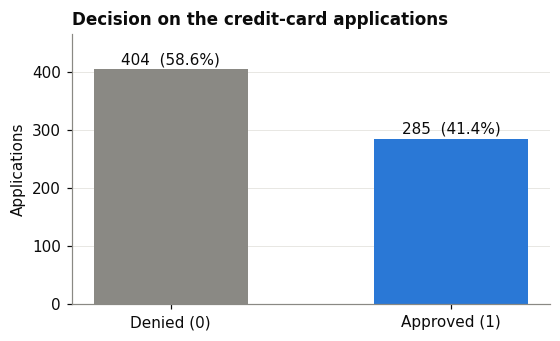

Approval rate: 41.4%
Baseline accuracy (always predict 'denied'): 58.6%


In [4]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()
baseline = 1 - rate                      # always predict "denied"

fig, ax = plt.subplots(figsize=(5.2, 3.2))
bars = ax.bar(["Denied (0)", "Approved (1)"], counts.values, color=[GRAY, BLUE], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v:,}  ({v / len(df):.1%})", ha="center", fontsize=10)
ax.set_ylim(0, counts.max() * 1.15); ax.set_ylabel("Applications"); ax.set_title("Decision on the credit-card applications")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

print(f"Approval rate: {rate:.1%}")
print(f"Baseline accuracy (always predict 'denied'): {baseline:.1%}")

🔍 **What to notice:** about **41%** of the applications were approved. A rule that says "deny everybody" is already right about **59%** of the time. That number is the bar to beat: a model with 60% accuracy is **not** useful, even though 60% sounds good.

### Step 1.2 — Each predictor against the outcome
📖 Group the applicants by the value of one predictor and compare the **approval rate** of each group. A trend means the predictor carries information.

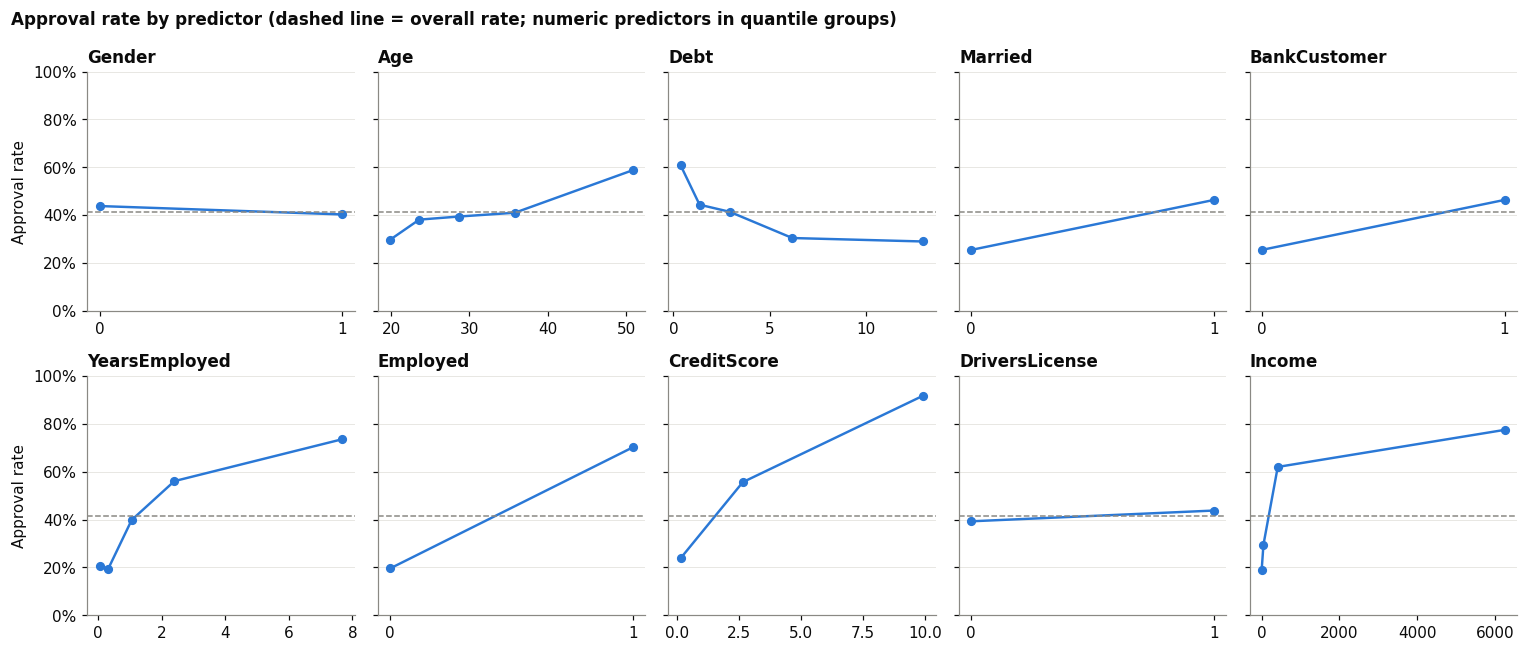

In [5]:
def rate_by(col, bins=5):
    """Approval rate by value (few distinct values) or by quantile bin (many values)."""
    d = pd.DataFrame({"x": df[col], "y": df[TARGET]})
    if d["x"].nunique() <= 8:
        g = d.groupby("x").agg(x=("x", "first"), y=("y", "mean"), n=("y", "size"))
    else:
        g = d.groupby(pd.qcut(d["x"], bins, duplicates="drop"), observed=True).agg(
            x=("x", "mean"), y=("y", "mean"), n=("y", "size"))
    return g

fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharey=True)
for ax, col in zip(axes.ravel(), PRED):
    g = rate_by(col)
    ax.plot(g["x"], g["y"], "-o", color=BLUE, lw=1.6, ms=5)
    ax.axhline(rate, color=GRAY, lw=1, ls="--")
    ax.set_title(col); ax.grid(axis="x", visible=False)
    if df[col].nunique() == 2: ax.set_xticks([0, 1])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1)
axes[0, 0].set_ylabel("Approval rate"); axes[1, 0].set_ylabel("Approval rate")
fig.suptitle("Approval rate by predictor (dashed line = overall rate; numeric predictors in quantile groups)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

🔍 **What to notice:**
- **Strong trends:** applicants with a credit score above 2.5 are approved **88%** of the time, against **25%** for the rest. Employed applicants are approved **70%** of the time (not employed: **20%**). Approval also climbs with `YearsEmployed` (from 21% in the shortest group to 74% in the longest) and with `Income` (19% to 78%).
- **Debt works in the logical direction:** the approval rate falls from **61%** in the lowest-debt group to **29%** in the highest. `Age` goes the other way: 30% in the youngest group and 59% in the oldest.
- **Weak or flat:** `Married` / `BankCustomer` (25% vs 46%) show a smaller but visible gap, while `Gender` (44% vs 40%) and `DriversLicense` (39% vs 44%) are almost flat.
These are first hints. The tree will separate overlapping effects.

### Step 1.3 — Duplicated predictors
📖 Two predictors that say the same thing compete for the same splits. A tree can use only one of them, so it is worth spotting them before reading the tree.

In [6]:
print(pd.crosstab(df["Employed"], df["CreditScore"] > 0, rownames=["Employed"], colnames=["CreditScore > 0"]).to_string())
print()
print("Applicants where Married and BankCustomer differ:", int((df["Married"] != df["BankCustomer"]).sum()))

CreditScore > 0  False  True 
Employed                     
0                  393      0
1                    0    296

Applicants where Married and BankCustomer differ: 0


🔍 **What to notice:** `Employed` and `CreditScore > 0` are the **same information**: all 393 applicants who are not employed have no score on file, and all 296 employed applicants have one. `Married` and `BankCustomer` are identical for all 689 applicants. When two predictors are identical, the tree picks one and the other gets **zero importance**. That does not mean the unused one is useless: it means it is redundant. Keep this in mind in Step 5.4.

## Section 2 — Partition the data
📖 A model must be judged on applicants it has **never seen**. We keep 20% of the data aside (test set) and use it only once, at the end.

### Step 2.1 — Split into training (80%) and test (20%)
📖 The **training set** grows the tree (and, in Section 4, is also where cross-validation happens); the **test set** measures the final tree on new data. A fixed seed makes the split reproducible, and `stratify` keeps the same approval rate in both sets.

In [7]:
X = df[PRED]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

summary = pd.DataFrame({"Applicants": [len(X_train), len(X_test)],
                        "Approved": [int(y_train.sum()), int(y_test.sum())],
                        "Approval rate": [y_train.mean(), y_test.mean()]}, index=["Training", "Test"])
summary["Approval rate"] = summary["Approval rate"].map("{:.1%}".format)
print(f"Seed = {SEED}"); print(summary.to_string())

Seed = 42
          Applicants  Approved Approval rate
Training         551       228         41.4%
Test             138        57         41.3%


✅ **Expected result:** 551 applicants for training and 138 for testing, with almost identical approval rates (41.4% and 41.3%).

🔍 **What to notice:** with only 138 test applicants, every test metric carries noise: one more correct decision moves accuracy by about 0.7%. Report the **seed** and the **size of each set** every time.

> ⚠️ **Watch out.** Never use the test set to choose the tree. Anything you decide after seeing test results (which depth, which variables) makes the test score optimistic. In Section 4 we choose the tree **inside the training set** with cross-validation.

### Step 2.2 — Do trees need standardized predictors?
📖 In Week 3 and Week 4 we standardized predictors to compare coefficients. A tree only asks "is this value above a cut-off?", and rescaling a variable does not change the order of its values. Let us check it instead of taking it on faith.

Take a look in lines 10-12: they show the CreditScore value where each tree (one using raw data and nother using standardized values) makes its first cut. The tree on the original data cuts at 2.5. The tree on standardized data cuts at about 0.02, but that is the same cut written in standard deviations.

When that 0.02 is converted back to original units (z × sd + mean), it gives 2.5 again, so both trees cut at the same CreditScore value.

In [8]:
scaler = StandardScaler().fit(X_train)                  # learn mean and sd from TRAIN only
Z_train = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
Z_test  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

t_raw = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(X_train, y_train)   # original units
t_std = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(Z_train, y_train)   # z-scores

print("Same predictions on the test set:", bool((t_raw.predict(X_test) == t_std.predict(Z_test)).all()))
print("Same number of leaves:", t_raw.get_n_leaves(), "vs", t_std.get_n_leaves())

f0 = t_raw.tree_.feature[0]; name0 = X.columns[f0]
back = t_std.tree_.threshold[0] * scaler.scale_[f0] + scaler.mean_[f0]
print(f"Root split on {name0}:  raw cut-off = {t_raw.tree_.threshold[0]:.3f}  |  z-score cut-off = {t_std.tree_.threshold[0]:.3f}"
      f"  -> {back:.3f} back in original units")

Same predictions on the test set: True
Same number of leaves: 15 vs 15
Root split on CreditScore:  raw cut-off = 2.500  |  z-score cut-off = 0.019  -> 2.500 back in original units


🔍 **What to notice:** the two trees make **exactly the same predictions** and have the same number of leaves. The z-score cut-off is just the original cut-off expressed in standard deviations; converted back, it is the same number. So for a tree we keep the **original units**, which also makes the rules readable ("CreditScore ≤ 2.5" means something; "CreditScore ≤ 0.02 standard deviations" does not).

> 💡 **Tip.** Standardizing matters for methods that compare distances or coefficient sizes (k-nearest neighbors, logistic regression coefficients). It is not needed for trees.

## Section 3 — How CART chooses a split and how to read a tree
📖 CART asks, at every node, the same question for every predictor: *which cut-off makes the two resulting groups as pure as possible?* Purity is measured with the **Gini index**, and the search is repeated inside every new group (recursive splitting).

### Step 3.1 — The Gini index by hand
📖 For a node with class proportions *pᵢ*: **Gini = 1 − Σ pᵢ²**. It is 0 for a pure node and 0.5 for a 50/50 node (two classes).

                                      Node  Gini
          Pure node: 0 denied, 10 approved 0.000
         Mostly pure: 1 denied, 9 approved 0.180
            Even mix: 5 denied, 5 approved 0.500
Our training set: 323 denied, 228 approved 0.485


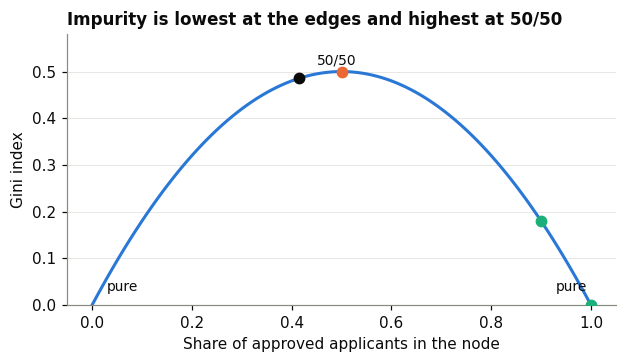

In [9]:
def gini(counts):
    """Gini index of a node from its class counts, e.g. [denied, approved]."""
    p = np.asarray(counts, dtype=float) / np.sum(counts)
    return 1 - np.sum(p ** 2)

n0, n1 = int((y_train == 0).sum()), int((y_train == 1).sum())
examples = [("Pure node: 0 denied, 10 approved", [0, 10]),
            ("Mostly pure: 1 denied, 9 approved", [1, 9]),
            ("Even mix: 5 denied, 5 approved", [5, 5]),
            (f"Our training set: {n0} denied, {n1} approved", [n0, n1])]
gtab = pd.DataFrame([{"Node": t, "Gini": gini(c)} for t, c in examples])
print(gtab.round(3).to_string(index=False))

p = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ax.plot(p, 1 - p ** 2 - (1 - p) ** 2, color=BLUE, lw=2)
for (t, c), col in zip(examples, [AQUA, AQUA, ORANGE, INK]):
    share = c[1] / sum(c); ax.scatter(share, gini(c), color=col, s=45, zorder=3)
ax.text(0.03, 0.03, "pure", fontsize=9); ax.text(0.45, 0.515, "50/50", fontsize=9); ax.text(0.93, 0.03, "pure", fontsize=9)
ax.set_xlabel("Share of approved applicants in the node"); ax.set_ylabel("Gini index"); ax.set_ylim(0, 0.58)
ax.set_title("Impurity is lowest at the edges and highest at 50/50"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

✅ **Expected result:** Gini = 0 (pure), 0.18 (one case in ten differs) and 0.5 (even mix), as in the video.

🔍 **What to notice:** the training set has 323 denied and 228 approved applicants, so its Gini is **0.485**, close to the 0.5 maximum: the whole group is quite mixed. A good split must produce two groups that are **purer** than this. The dots on the curve show where each example sits.

### Step 3.2 — The split search: every cut-off, every predictor
📖 Sort the values of a predictor, take the **midpoint between consecutive values** as a candidate cut-off, compute the **weighted Gini** of the two groups (weights = group sizes) and keep the cut-off with the smallest score. Do it for every predictor and keep the best.

Gini before any split: 0.485

                cut_off  weighted_gini  gini_reduction
CreditScore       2.500          0.329           0.156
Employed          0.500          0.367           0.118
Income          148.500          0.376           0.109
YearsEmployed     1.188          0.425           0.060
Debt              1.520          0.456           0.029
Age              38.625          0.465           0.020
BankCustomer      0.500          0.470           0.015
Married           0.500          0.470           0.015
Gender            0.500          0.485           0.000
DriversLicense    0.500          0.485           0.000

scikit-learn's first split: CreditScore <= 2.50


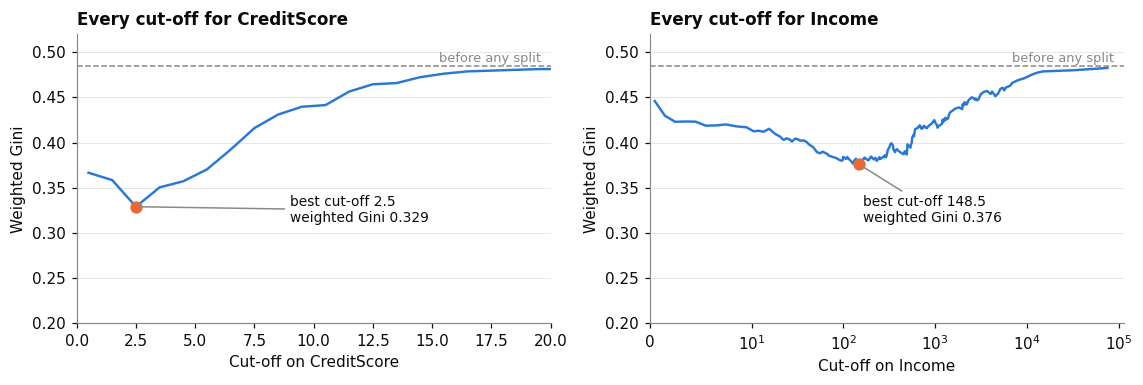

In [10]:
def best_split(x, y):
    """Weighted Gini of the two groups for every candidate cut-off of one predictor."""
    order = np.argsort(x.values, kind="mergesort")
    xs, ys = x.values[order], y.values[order]
    n, tot1 = len(ys), ys.sum()
    left1 = np.cumsum(ys)
    out = []
    for i in range(n - 1):
        if xs[i] == xs[i + 1]:
            continue                                              # no cut-off between equal values
        nl, a_l = i + 1, left1[i]
        nr, a_r = n - nl, tot1 - a_l
        w = nl / n * gini([nl - a_l, a_l]) + nr / n * gini([nr - a_r, a_r])
        out.append(((xs[i] + xs[i + 1]) / 2, w))
    return pd.DataFrame(out, columns=["cut_off", "weighted_gini"])

root_gini = gini([n0, n1])
searches = {c: best_split(X_train[c], y_train) for c in PRED}
split_tbl = pd.DataFrame({c: s.loc[s["weighted_gini"].idxmin()] for c, s in searches.items()}).T
split_tbl["gini_reduction"] = root_gini - split_tbl["weighted_gini"]
split_tbl = split_tbl.sort_values("weighted_gini")
print(f"Gini before any split: {root_gini:.3f}\n")
print(split_tbl.round(3).to_string())

stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train)
print(f"\nscikit-learn's first split: {X.columns[stump.tree_.feature[0]]} <= {stump.tree_.threshold[0]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, col, kw in [(axes[0], "CreditScore", {"xlim": (0, 20)}), (axes[1], "Income", {"xscale": "symlog"})]:
    s = searches[col]; b = s.loc[s["weighted_gini"].idxmin()]
    ax.plot(s["cut_off"], s["weighted_gini"], color=BLUE, lw=1.6)
    ax.axhline(root_gini, color=GRAY, ls="--", lw=1); ax.text(0.98, root_gini + 0.004, "before any split", ha="right", transform=ax.get_yaxis_transform(), fontsize=8.5, color=GRAY)
    ax.scatter([b["cut_off"]], [b["weighted_gini"]], color=ORANGE, s=50, zorder=3)
    ax.annotate(f"best cut-off {b['cut_off']:.1f}\nweighted Gini {b['weighted_gini']:.3f}", (b["cut_off"], b["weighted_gini"]),
                xytext=(0.45, 0.35), textcoords="axes fraction", fontsize=9, arrowprops=dict(arrowstyle="-", color=GRAY),
                bbox=dict(fc="white", ec="none", pad=1.5))
    ax.set_title(f"Every cut-off for {col}"); ax.set_xlabel(f"Cut-off on {col}"); ax.set_ylabel("Weighted Gini"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0.2, 0.52)
    if "xlim" in kw: ax.set_xlim(*kw["xlim"])
    if "xscale" in kw: ax.set_xscale("symlog", linthresh=10); ax.set_xlim(0, s["cut_off"].max() * 1.5)
plt.tight_layout(); plt.show()

✅ **Expected result:** the best first split is **`CreditScore` ≤ 2.5**, and scikit-learn finds exactly the same one.

🔍 **What to notice:** the table is the whole CART "tournament" for the first split. Each predictor's best cut-off brings the Gini from **0.485** down to its weighted score; `CreditScore` wins with **0.329** (a reduction of 0.156), followed by `Employed` (0.367). The curves show the same search for two predictors: the best cut-off is the lowest point, and cut-offs near the ends of the range barely help (the curve hugs the dashed line) because they peel off only a few applicants. After this first split, CART repeats the whole search **inside each of the two groups**.

> 💡 **Tip.** Look at where the `CreditScore` cut-off falls: 2.5 separates "no or very low score" from "real credit history". CART found a business-meaningful threshold without being told.

### Step 3.3 — Read a tree: the anatomy of a node
📖 Every box shows: the **question** (left branch = *yes*, right branch = *no*), the **gini** of the node, the number of **samples** that reached it, the **value** (how many applicants of each class: `[denied, approved]`) and the majority **class**. The color gets darker as the node gets purer.

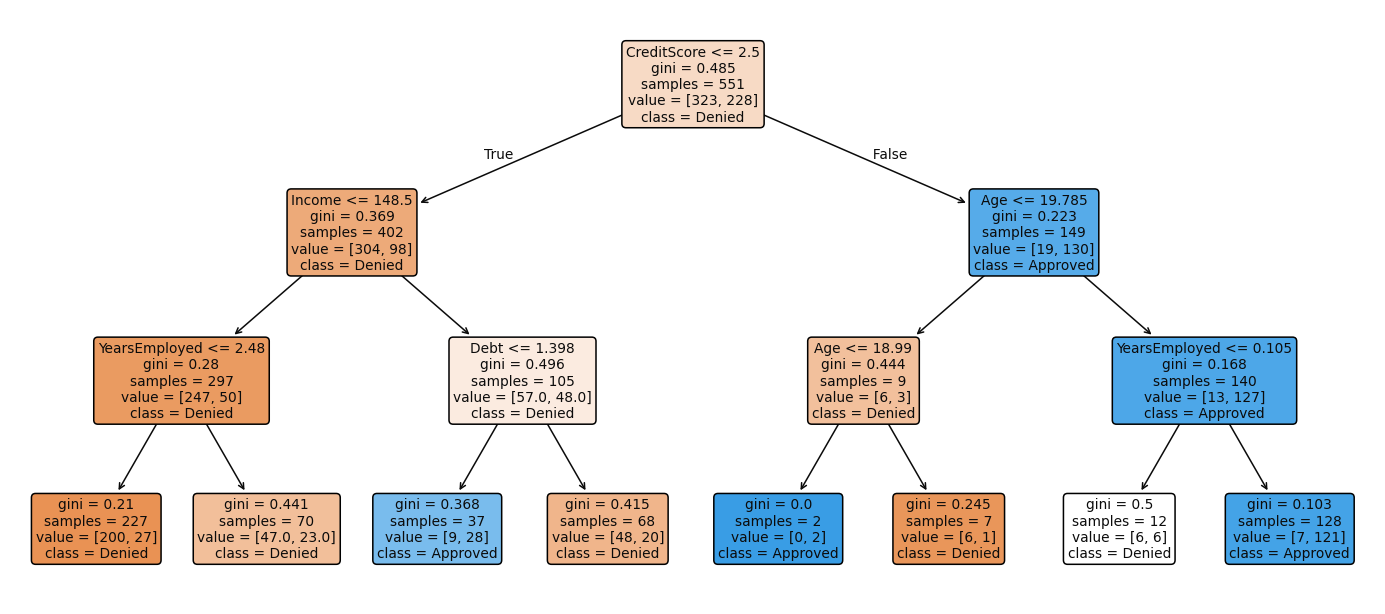

In [11]:
tree3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)   # depth 3 only to fit on the page

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree3, feature_names=list(X.columns), class_names=["Denied", "Approved"],
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

🔍 **What to notice (read the root box):**
- **`CreditScore <= 2.5`** is the question. The 402 applicants for whom the answer is *yes* go to the left; the other 149 go to the right.
- **`samples = 551`**: all the training applicants reach the root. **`value = [323, 228]`**: 323 denied and 228 approved. **`gini = 0.485`** is the number from Step 3.1.
- The majority class is **Denied**, so the root is colored orange. Follow any path from the root down to a box with no further question (a **leaf**): that path is one rule. Leaves with a `gini` close to 0 are almost pure.

> 💡 **Tip.** This depth-3 tree is only here so it fits on the page. The **right size** for the tree is chosen properly in Section 4.

### Step 3.4 — What happens if we let the tree grow?
📖 Left alone, CART keeps splitting until every leaf is pure. It then **memorizes** the training data, noise included.

In [12]:
tree_full = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)    # no limit on growth
tf = tree_full.tree_
is_leaf = tf.children_left == -1
print(f"Depth: {tree_full.get_depth()} | nodes: {tf.node_count} | leaves: {tree_full.get_n_leaves()}")
print(f"Leaves that hold a single applicant: {int((tf.n_node_samples[is_leaf] == 1).sum())}")
print(f"Leaves that hold at most 2 applicants: {int((tf.n_node_samples[is_leaf] <= 2).sum())}")
print(f"Accuracy on the TRAINING set: {accuracy_score(y_train, tree_full.predict(X_train)):.3f}")

Depth: 15 | nodes: 191 | leaves: 96
Leaves that hold a single applicant: 31
Leaves that hold at most 2 applicants: 61
Accuracy on the TRAINING set: 1.000


🔍 **What to notice:** the full tree reaches depth **15** with **96 leaves**, and **31** of those leaves hold a single applicant: the tree built a special rule for one person. Its training accuracy is **1.000**, a perfect score that means little. Whether it works on *new* applicants is a different question, and the training set cannot answer it. Section 4 shows how to find out without touching the test set.

## Section 4 — How big should the tree be? Cross-validation
📖 **Cross-validation (CV)** estimates how a model will do on new data **using only the training set**, by repeating a train-and-validate round several times. We use it to compare trees of different sizes and pick the one that generalizes best.

### Step 4.1 — What k-fold cross-validation does
📖 Split the training set into **k folds** of similar size (stratified: each fold keeps the approval rate). In round 1, **train on folds 2 to k** and **validate on fold 1**. In round 2, validate on fold 2, and so on, so that **every applicant is used for validation exactly once**. The k scores are then averaged.

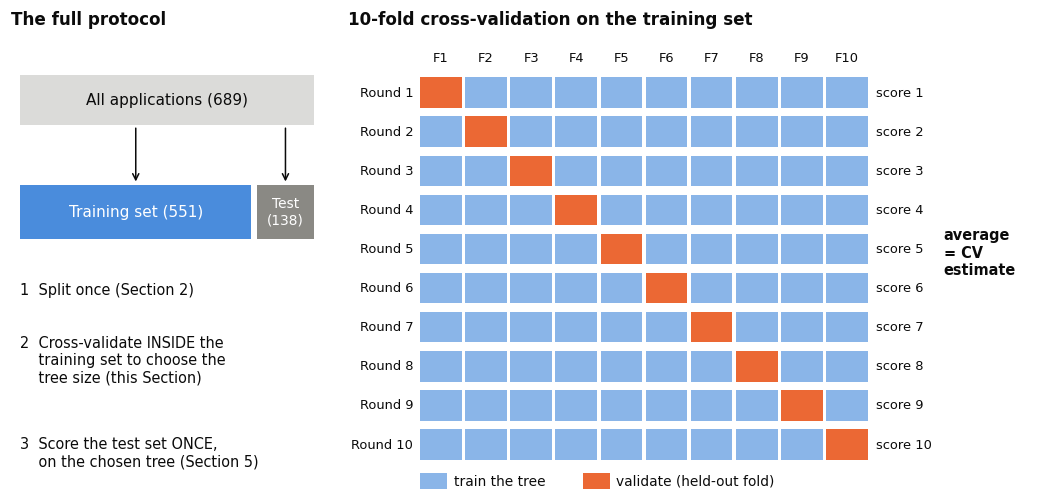

In [13]:
k = 10
fig = plt.figure(figsize=(12, 5.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.2], wspace=0.05)

# --- left: the whole protocol --------------------------------------------------------------
a = fig.add_subplot(gs[0]); a.axis("off"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.grid(False)
a.set_title("The full protocol")
a.add_patch(Rectangle((0.03, 0.80), 0.94, 0.11, fc=GRAY, alpha=0.30, ec="none"))
a.text(0.5, 0.855, f"All applications ({len(df)})", ha="center", va="center", fontsize=10)
a.add_patch(Rectangle((0.03, 0.55), 0.74, 0.12, fc=BLUE, alpha=0.85, ec="none"))
a.text(0.40, 0.61, f"Training set ({len(X_train)})", ha="center", va="center", color="white", fontsize=10)
a.add_patch(Rectangle((0.79, 0.55), 0.18, 0.12, fc=GRAY, ec="none"))
a.text(0.88, 0.61, f"Test\n({len(X_test)})", ha="center", va="center", color="white", fontsize=9)
a.annotate("", xy=(0.40, 0.67), xytext=(0.40, 0.80), arrowprops=dict(arrowstyle="->", color=INK))
a.annotate("", xy=(0.88, 0.67), xytext=(0.88, 0.80), arrowprops=dict(arrowstyle="->", color=INK))
a.text(0.03, 0.43, "1  Split once (Section 2)", fontsize=9.5)
a.text(0.03, 0.34, "2  Cross-validate INSIDE the\n    training set to choose the\n    tree size (this Section)", fontsize=9.5, va="top")
a.text(0.03, 0.12, "3  Score the test set ONCE,\n    on the chosen tree (Section 5)", fontsize=9.5, va="top")

# --- right: the k rounds --------------------------------------------------------------------
b = fig.add_subplot(gs[1]); b.set_xlim(-1.6, k + 3.6); b.set_ylim(-0.8, k + 0.9); b.axis("off"); b.grid(False)
b.set_title(f"{k}-fold cross-validation on the training set")
for r in range(k):
    for c in range(k):
        b.add_patch(Rectangle((c, k - 1 - r), 0.92, 0.78, fc=ORANGE if c == r else BLUE, alpha=1.0 if c == r else 0.55, ec="none"))
    b.text(-0.15, k - 1 - r + 0.39, f"Round {r + 1}", ha="right", va="center", fontsize=8.5)
    b.text(k + 0.1, k - 1 - r + 0.39, f"score {r + 1}", ha="left", va="center", fontsize=8.5)
for c in range(k):
    b.text(c + 0.46, k + 0.12, f"F{c + 1}", ha="center", va="bottom", fontsize=8.5)
b.add_patch(Rectangle((0.0, -0.75), 0.6, 0.4, fc=BLUE, alpha=0.55, ec="none")); b.text(0.75, -0.55, "train the tree", va="center", fontsize=9)
b.add_patch(Rectangle((3.6, -0.75), 0.6, 0.4, fc=ORANGE, ec="none")); b.text(4.35, -0.55, "validate (held-out fold)", va="center", fontsize=9)
b.text(k + 1.6, k / 2 + 0.3, "average\n= CV\nestimate", ha="left", va="center", fontsize=9.5, fontweight="bold")
plt.show()

🔍 **What to notice:** the training set (not the test set) is what gets cut into folds. In every round the tree is trained on about 90% of the training applicants and scored on the 10% it did not see, so **each score is an honest estimate**. The **average of the 10 scores** is the cross-validated estimate, and the spread of the 10 scores tells us how much to trust it. The test set stays locked away until the very end.

> 💡 **Tip.** Why not a single validation split? Because one split can be lucky or unlucky. With 10 rounds every applicant is validated once and the luck averages out. More folds means more training data per round but more computing time; **k = 5 or 10** is the usual choice.

### Step 4.2 — Run the 10 rounds by hand for one tree
📖 A loop makes the idea concrete: for each round, train on 9 folds, score on the held-out fold. We use a depth-4 tree as the example and report **accuracy** and **AUC** on each held-out fold.

       trained on  validated on  accuracy    AUC
round                                           
1             495            56     0.839  0.845
2             496            55     0.800  0.757
3             496            55     0.764  0.851
4             496            55     0.691  0.685
5             496            55     0.727  0.720
6             496            55     0.800  0.855
7             496            55     0.745  0.758
8             496            55     0.855  0.872
9             496            55     0.891  0.845
10            496            55     0.818  0.846

CV AUC = 0.804   (standard error 0.021)   |   CV accuracy = 0.793
cross_validate agrees: AUC 0.804 | accuracy 0.793


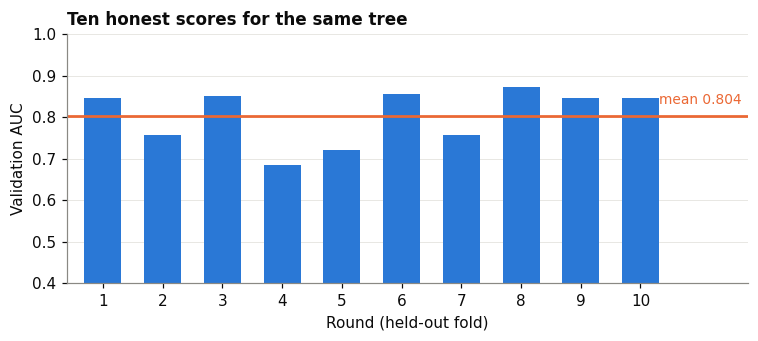

In [14]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)      # the same folds will be reused in Step 4.3

rows = []
for r, (idx_train, idx_valid) in enumerate(skf.split(X_train, y_train), start=1):
    m = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(X_train.iloc[idx_train], y_train.iloc[idx_train])
    yv = y_train.iloc[idx_valid]
    rows.append({"round": r, "trained on": len(idx_train), "validated on": len(idx_valid),
                 "accuracy": accuracy_score(yv, m.predict(X_train.iloc[idx_valid])),
                 "AUC": roc_auc_score(yv, m.predict_proba(X_train.iloc[idx_valid])[:, 1])})
fold_tbl = pd.DataFrame(rows).set_index("round")
print(fold_tbl.round(3).to_string())

auc_mean, auc_se = fold_tbl["AUC"].mean(), fold_tbl["AUC"].std(ddof=1) / np.sqrt(len(fold_tbl))
print(f"\nCV AUC = {auc_mean:.3f}   (standard error {auc_se:.3f})   |   CV accuracy = {fold_tbl['accuracy'].mean():.3f}")

# scikit-learn does the same loop in one line
check = cross_validate(DecisionTreeClassifier(max_depth=4, random_state=SEED), X_train, y_train, cv=skf, scoring=["accuracy", "roc_auc"])
print(f"cross_validate agrees: AUC {check['test_roc_auc'].mean():.3f} | accuracy {check['test_accuracy'].mean():.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(fold_tbl.index, fold_tbl["AUC"], color=BLUE, width=0.62)
ax.axhline(auc_mean, color=ORANGE, lw=1.8); ax.text(11.7, auc_mean + 0.02, f"mean {auc_mean:.3f}", ha="right", va="bottom", fontsize=9, color=ORANGE)
ax.set_xticks(fold_tbl.index); ax.set_xlabel("Round (held-out fold)"); ax.set_ylabel("Validation AUC"); ax.set_ylim(0.4, 1.0)
ax.set_title("Ten honest scores for the same tree"); ax.grid(axis="x", visible=False); ax.set_xlim(0.4, 11.8)
plt.tight_layout(); plt.show()

✅ **Expected result:** each round trains on about 496 applicants and validates on about 55; the by-hand average and `cross_validate` agree.

🔍 **What to notice:** the same tree scores between **0.68 and 0.87** in AUC depending on which fold is held out, and between 0.69 and 0.89 in accuracy. A single validation split would have given you any one of those numbers. The average (**AUC 0.804**) with its **standard error (0.021)** is a much more reliable summary. The standard error will matter in the next step.

### Step 4.3 — Choose the tree size with cross-validation
📖 The "length" of a tree is its **depth** (`max_depth`). For every depth from 1 to 12 we run the same 10-fold CV and record the **training** score and the **cross-validated** score. We score with **AUC** because the bank needs a good *ranking* of applicants; accuracy is shown next to it.

           leaves  train_acc  cv_acc  se_acc  train_auc  cv_auc  se_auc
max_depth                                                              
1               2      0.788   0.788   0.009      0.756   0.756   0.010
2               4      0.797   0.768   0.013      0.819   0.790   0.017
3               8      0.832   0.777   0.013      0.863   0.800   0.020
4              15      0.863   0.793   0.019      0.902   0.804   0.021
5              24      0.886   0.799   0.013      0.927   0.796   0.027
6              37      0.906   0.791   0.020      0.953   0.784   0.020
7              50      0.932   0.770   0.016      0.972   0.746   0.026
8              63      0.953   0.770   0.024      0.984   0.756   0.028
9              70      0.967   0.761   0.019      0.990   0.743   0.022
10             77      0.975   0.750   0.023      0.995   0.740   0.025
11             85      0.983   0.748   0.020      0.998   0.736   0.021
12             88      0.991   0.748   0.020      0.999   0.740 

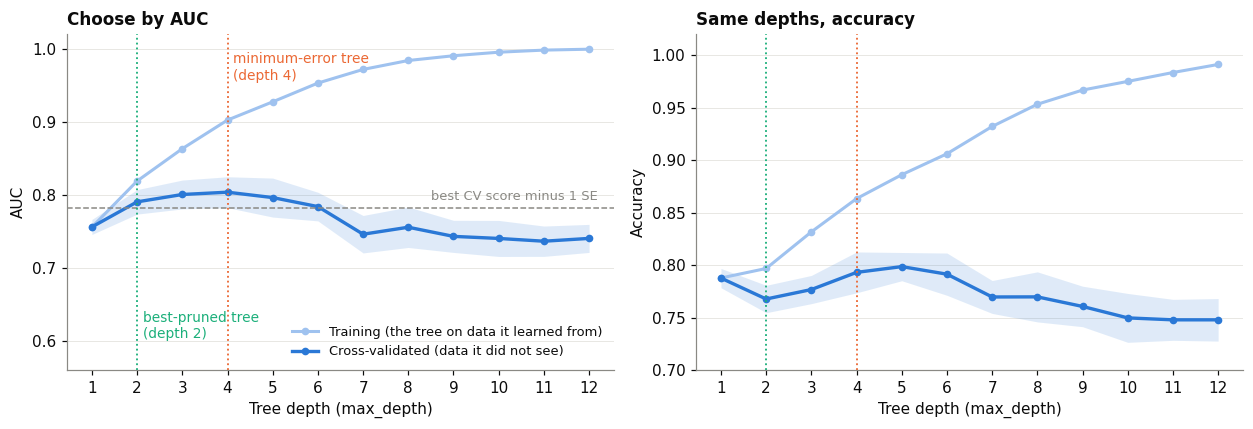


If we had scored with accuracy: minimum-error depth 5, best-pruned depth 1.


In [15]:
rows = []
for d in range(1, 13):
    r = cross_validate(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train, cv=skf,
                       scoring=["accuracy", "roc_auc"], return_train_score=True)
    rows.append({"max_depth": d,
                 "leaves": DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train).get_n_leaves(),
                 "train_acc": r["train_accuracy"].mean(), "cv_acc": r["test_accuracy"].mean(),
                 "se_acc": r["test_accuracy"].std(ddof=1) / np.sqrt(10),
                 "train_auc": r["train_roc_auc"].mean(), "cv_auc": r["test_roc_auc"].mean(),
                 "se_auc": r["test_roc_auc"].std(ddof=1) / np.sqrt(10)})
cv_tbl = pd.DataFrame(rows).set_index("max_depth")

# The two classic choices
best_depth = int(cv_tbl["cv_auc"].idxmax())                                   # minimum-error tree: best CV score
cutoff = cv_tbl.loc[best_depth, "cv_auc"] - cv_tbl.loc[best_depth, "se_auc"]  # best score minus one standard error
pruned_depth = int(cv_tbl.index[cv_tbl["cv_auc"] >= cutoff].min())            # best-pruned tree: simplest tree above that line

print(cv_tbl.round(3).to_string())
print(f"\nMinimum-error tree : depth {best_depth}  (CV AUC {cv_tbl.loc[best_depth, 'cv_auc']:.3f})")
print(f"One-SE line        : {cutoff:.3f}")
print(f"Best-pruned tree   : depth {pruned_depth}  (CV AUC {cv_tbl.loc[pruned_depth, 'cv_auc']:.3f}, {cv_tbl.loc[pruned_depth, 'leaves']} leaves)")

cvf = cross_validate(DecisionTreeClassifier(random_state=SEED), X_train, y_train, cv=skf, scoring=["accuracy", "roc_auc"], return_train_score=True)
print(f"Full-grown tree    : train accuracy {cvf['train_accuracy'].mean():.3f} | CV accuracy {cvf['test_accuracy'].mean():.3f} | CV AUC {cvf['test_roc_auc'].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, (tr, cvc, se, lab) in zip(axes, [("train_auc", "cv_auc", "se_auc", "AUC"), ("train_acc", "cv_acc", "se_acc", "Accuracy")]):
    ax.plot(cv_tbl.index, cv_tbl[tr], color=LIGHT_BLUE, lw=2, marker="o", ms=4, label="Training (the tree on data it learned from)")
    ax.plot(cv_tbl.index, cv_tbl[cvc], color=BLUE, lw=2.2, marker="o", ms=4, label="Cross-validated (data it did not see)")
    ax.fill_between(cv_tbl.index, cv_tbl[cvc] - cv_tbl[se], cv_tbl[cvc] + cv_tbl[se], color=BLUE, alpha=0.15, lw=0)
    ax.set_xticks(cv_tbl.index); ax.set_xlabel("Tree depth (max_depth)"); ax.set_ylabel(lab); ax.grid(axis="x", visible=False)
axes[0].axhline(cutoff, color=GRAY, ls="--", lw=1); axes[0].text(12.2, cutoff + 0.006, "best CV score minus 1 SE", ha="right", va="bottom", fontsize=8.5, color=GRAY)
for ax in axes:
    ax.axvline(best_depth, color=ORANGE, lw=1.2, ls=":"); ax.axvline(pruned_depth, color=AQUA, lw=1.2, ls=":")
axes[0].text(best_depth + 0.12, 0.995, f"minimum-error tree\n(depth {best_depth})", color=ORANGE, fontsize=9, va="top")
axes[0].text(pruned_depth + 0.12, 0.60, f"best-pruned tree\n(depth {pruned_depth})", color=AQUA, fontsize=9, va="bottom")
axes[0].set_ylim(0.56, 1.02); axes[1].set_ylim(0.70, 1.02)
axes[0].set_title("Choose by AUC"); axes[1].set_title("Same depths, accuracy")
axes[0].legend(frameon=False, loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

# What would an accuracy-based choice have given?
b_acc = int(cv_tbl["cv_acc"].idxmax()); c_acc = cv_tbl.loc[b_acc, "cv_acc"] - cv_tbl.loc[b_acc, "se_acc"]
p_acc = int(cv_tbl.index[cv_tbl["cv_acc"] >= c_acc].min())
print(f"\nIf we had scored with accuracy: minimum-error depth {b_acc}, best-pruned depth {p_acc}.")

**se = Standard Error**

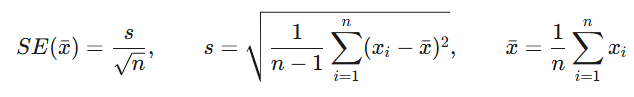

**Where:**

$x_i$ is one observed value.

$\bar{x}$ is their mean.

$s$ is the sample standard deviation (divide by $n-1$).

$n$ is the number of values.

**Applying this definition to our CV exercise (using AUC):**

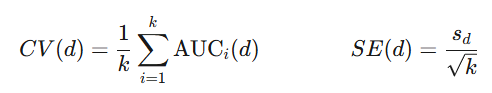

Here $n = k = 10$ folds and $x_i$ is the score (AUC or accuracy) on fold $i$, for one tree depth $d$.

Let's see the example for the calculation of the ***se*** of a max_depth = 2 and 4 leaves:

***Cross-validated AUC → cv_auc = 0.790, se_auc = 0.017***

| Fold | AUC xᵢ | xᵢ − x̄ | (xᵢ − x̄)² |
|:---:|:---:|:---:|:---:|
| 1 | 0.8439 | +0.0536 | 0.00287 |
| 2 | 0.7643 | −0.0260 | 0.00068 |
| 3 | 0.7459 | −0.0444 | 0.00197 |
| 4 | 0.6970 | −0.0933 | 0.00870 |
| 5 | 0.7283 | −0.0620 | 0.00385 |
| 6 | 0.8240 | +0.0338 | 0.00114 |
| 7 | 0.8043 | +0.0141 | 0.00020 |
| 8 | 0.8465 | +0.0562 | 0.00316 |
| 9 | 0.8388 | +0.0485 | 0.00236 |
| 10 | 0.8099 | +0.0196 | 0.00038 |
| **Sum** | **7.9029** | ≈ 0 | **0.02530** |

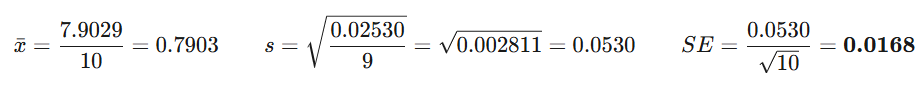

✅ **Expected result:** training AUC keeps climbing toward 1 as the tree deepens, while the cross-validated AUC rises, peaks and then falls.

🔍 **What to notice:**
- **The overfitting signal:** at depth 12 the training AUC is **0.999**, but the cross-validated AUC is only **0.740**. The fully grown tree scores 1.000 in training accuracy and only **0.742** in cross-validation. The widening gap between the two lines is overfitting.
- **Minimum-error tree:** the best cross-validated AUC is **0.804**, at **depth 4** (15 leaves).
- **Best-pruned tree:** the shaded band is one standard error. The simplest tree whose CV AUC stays above the dashed line (**0.782**) has **depth 2** (4 leaves, CV AUC 0.790). The difference with the best score is smaller than the noise of the estimate, so the extra branches are not worth their risk.
- **Which one?** The video recommends the best-pruned tree as the safer pick, and we will use it as our final model. In Section 5 we compare all three trees on the test set.

> 💡 **Tip.** The last line of the output shows the same exercise scored with accuracy: the minimum-error depth is 5 and the best-pruned depth is **1**. The metric you choose changes the answer. Accuracy only sees whether a decision is right; AUC also sees how well the tree ranks applicants, and a tree with a single question can only give two different probabilities. For a bank that must rank applicants, AUC is the better yardstick here.

> ⚠️ **Watch out.** Cross-validation never touches the test set. Every number in this step came from the training applicants only.

### Step 4.4 — Refit the chosen tree on the whole training set
📖 Cross-validation was only the selection tool. The final model is a **new tree** with the chosen depth, fitted on **all** the training applicants. We also fit the minimum-error tree to compare it later.

Final tree: depth 2 | 4 leaves | variables used: ['Age', 'CreditScore', 'Income']


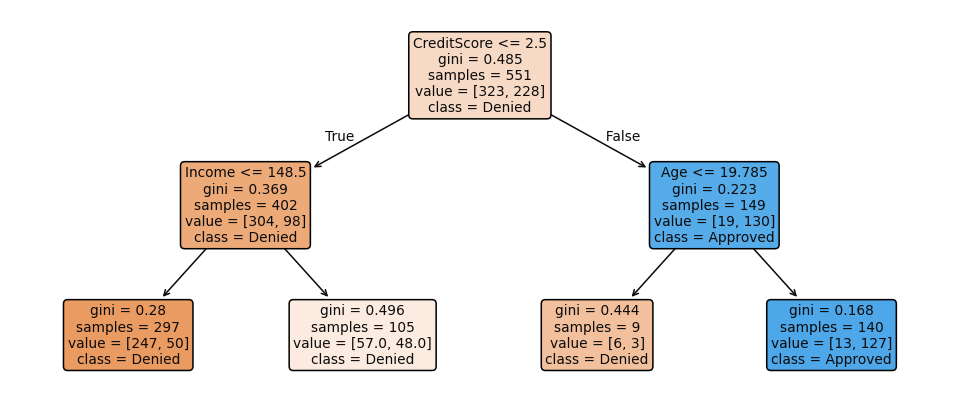

In [17]:
final_tree = DecisionTreeClassifier(max_depth=pruned_depth, random_state=SEED).fit(X_train, y_train)   # best-pruned tree = our model
tree_min   = DecisionTreeClassifier(max_depth=best_depth,   random_state=SEED).fit(X_train, y_train)   # minimum-error tree, for comparison

used = sorted({X.columns[f] for f in final_tree.tree_.feature if f >= 0})
print(f"Final tree: depth {final_tree.get_depth()} | {final_tree.get_n_leaves()} leaves | variables used: {used}")

fig, ax = plt.subplots(figsize=(11, 4.6))
plot_tree(final_tree, feature_names=list(X.columns), class_names=["Denied", "Approved"], filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

🔍 **What to notice:** the final tree has **4 leaves** and uses only **3 of the 10 predictors**: `Age`, `CreditScore`, `Income`. Nothing in the process told the tree to ignore the others: they simply did not lower the Gini enough to earn a split. Compare it with the 96-leaf tree of Step 3.4: it is far smaller, and as you will see in the next Section, it generalizes better.

## Section 5 — Evaluate the chosen tree on applicants it has never seen
📖 Only now do we open the test set. The tree turns every applicant into a **probability of approval**: the share of approved training applicants in the leaf where the applicant lands. With the usual threshold of **0.5**, probability ≥ 0.5 means *approve*.

### Step 5.1 — Confusion matrix and metrics on the test set
📖 Rows are what really happened, columns are what the tree predicted. TP = approved and predicted approved; FP = denied but predicted approved (risky approval); FN = approved but predicted denied (lost customer); TN = denied and predicted denied. Definitions of accuracy, precision, recall and F1 are as in the Week 4 lab.

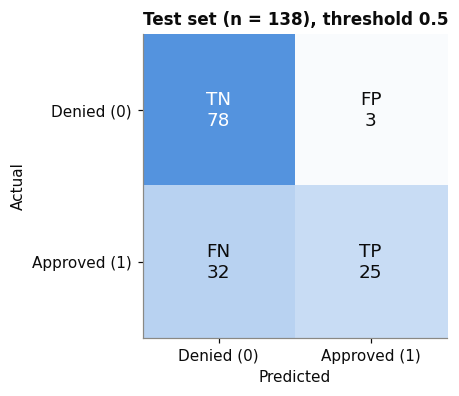

{'TN': 78, 'FP': 3, 'FN': 32, 'TP': 25, 'Accuracy': 0.746, 'Precision': 0.893, 'Recall': 0.439, 'F1': 0.588}
Baseline accuracy (always 'denied') on the test set: 0.587


In [18]:
THR = 0.5
p_train = final_tree.predict_proba(X_train)[:, 1]
p_test  = final_tree.predict_proba(X_test)[:, 1]

def metrics_at(y_true, p, thr=0.5):
    """Confusion-matrix counts and the four metrics at a threshold (positive class = 1)."""
    pred = (np.asarray(p) >= thr).astype(int)
    TN, FP, FN, TP = confusion_matrix(y_true, pred).ravel()
    acc  = (TP + TN) / (TP + TN + FP + FN)
    prec = TP / (TP + FP) if TP + FP else 0.0
    rec  = TP / (TP + FN) if TP + FN else 0.0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"TN": int(TN), "FP": int(FP), "FN": int(FN), "TP": int(TP),
            "Accuracy": float(acc), "Precision": float(prec), "Recall": float(rec), "F1": float(f1)}

def cm_plot(cm, ax, title):
    ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("w_b", ["#ffffff", BLUE]), vmin=0, vmax=cm.max() * 1.25)
    labs = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labs[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() * 0.6 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Denied (0)", "Approved (1)"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Denied (0)", "Approved (1)"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title); ax.grid(False)

cm_test = confusion_matrix(y_test, (p_test >= THR).astype(int))
fig, ax = plt.subplots(figsize=(4.4, 3.7)); cm_plot(cm_test, ax, f"Test set (n = {len(y_test)}), threshold {THR}")
plt.tight_layout(); plt.show()

m_test = metrics_at(y_test, p_test, THR)
print({k: (int(v) if k in ("TN", "FP", "FN", "TP") else round(v, 3)) for k, v in m_test.items()})
print(f"Baseline accuracy (always 'denied') on the test set: {1 - y_test.mean():.3f}")

🔍 **What to notice:** of the 138 test applicants the tree decided 103 correctly (accuracy **0.746**, against a baseline of 0.587). It approved 28 applicants and 25 of them really had been approved (precision **0.893**). It **missed 32** applicants who were approved (false negatives) and made **3 risky approvals** (false positives). Recall is **0.439**: at threshold 0.5 the tree finds about 44% of the applicants who were approved, so accuracy alone hides how many good customers it would turn away.

### Step 5.2 — Training vs test: is the chosen tree really better?
📖 The rule of thumb used in the course: a training accuracy **more than 5 points above** the test accuracy suggests overfitting; poor scores on both suggest underfitting. We compare the three trees of Section 4 side by side.

In [19]:
def diagnose(train_acc, test_acc, baseline, gap_limit=0.05, margin=0.05):
    """Rule-of-thumb diagnosis (not a statistical test)."""
    gap = train_acc - test_acc
    if gap > gap_limit:
        return "OVERFITTING"
    if train_acc < baseline + margin and test_acc < baseline + margin:
        return "UNDERFITTING"
    return "WELL FITTED"

base_train = 1 - y_train.mean()
trees = {"Full-grown tree": tree_full,
         f"Minimum-error tree (depth {best_depth})": tree_min,
         f"Best-pruned tree (depth {pruned_depth})": final_tree}

rows = []
for name, m in trees.items():
    ptr, pte = m.predict_proba(X_train)[:, 1], m.predict_proba(X_test)[:, 1]
    a_tr, a_te = metrics_at(y_train, ptr)["Accuracy"], metrics_at(y_test, pte)["Accuracy"]
    rows.append({"Tree": name, "Leaves": m.get_n_leaves(),
                 "Train acc.": a_tr, "Test acc.": a_te, "Gap": a_tr - a_te,
                 "Train AUC": roc_auc_score(y_train, ptr), "Test AUC": roc_auc_score(y_test, pte),
                 "Diagnosis": diagnose(a_tr, a_te, base_train)})
cmp_tbl = pd.DataFrame(rows).set_index("Tree")
print(cmp_tbl.round(3).to_string())

                              Leaves  Train acc.  Test acc.    Gap  Train AUC  Test AUC    Diagnosis
Tree                                                                                                
Full-grown tree                   96       1.000      0.710  0.290      1.000     0.696  OVERFITTING
Minimum-error tree (depth 4)      15       0.858      0.768  0.090      0.898     0.772  OVERFITTING
Best-pruned tree (depth 2)         4       0.793      0.746  0.047      0.823     0.789  WELL FITTED


🔍 **What to notice:**
- **Full-grown tree** (96 leaves): training accuracy 1.000, test accuracy only **0.710** (gap 0.290) and test AUC **0.696**. Diagnosis: **OVERFITTING**. It memorized.
- **Minimum-error tree** (15 leaves): test accuracy 0.768, test AUC 0.772, gap 0.090 (overfitting).
- **Best-pruned tree** (4 leaves): test accuracy 0.746, test AUC **0.789**, gap 0.047 (well fitted). It is the simplest of the three and has the best test AUC: the extra branches of the deeper trees did not pay off on new applicants.
- Pruning gives up some training accuracy (1.000 to 0.793) in exchange for a much smaller drop on new data. With only 138 test applicants, differences of one or two points are within the noise; the **AUC ordering** and the **size of the gaps** are the reliable message.

> 💡 **Tip.** The 5-point rule is a rule of thumb, not a test. A tree can be flagged because its training score is high *and* have a higher test accuracy than a simpler tree. Always read the gap together with the test score and the AUC.

### Step 5.3 — ROC curves of the three trees
📖 The ROC curve shows recall against the false-alarm rate for **every** threshold; AUC is the area under it (0.5 = random guessing, 1 = perfect ranking). A tree with few leaves gives few distinct probabilities, so its curve has few corners.

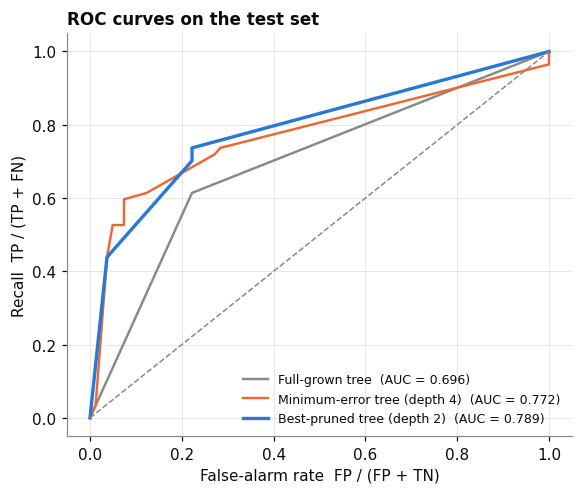

In [20]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
for (name, m), col in zip(trees.items(), [GRAY, ORANGE, BLUE]):
    pte = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pte)
    ax.plot(fpr, tpr, color=col, lw=2.2 if m is final_tree else 1.6, label=f"{name}  (AUC = {roc_auc_score(y_test, pte):.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
ax.set_xlabel("False-alarm rate  FP / (FP + TN)"); ax.set_ylabel("Recall  TP / (TP + FN)")
ax.set_title("ROC curves on the test set"); ax.legend(frameon=False, loc="lower right", fontsize=8.2); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

🔍 **What to notice:** all three curves are well above the diagonal, so every tree ranks applicants better than chance. The best-pruned tree (blue) reaches **AUC 0.789**, against 0.772 for the minimum-error tree and **0.696** for the full-grown tree. The curve of a small tree is made of a few long straight segments because it can only output a few different probabilities.

### Step 5.4 — Which variables does the tree use?
📖 **Variable importance** adds up, for each predictor, how much Gini it removed in all its splits (the total is 1). It ranks the predictors and shows which ones the tree never needed.

                Best-pruned tree  Full-grown tree
CreditScore                0.823            0.359
Income                     0.124            0.114
Age                        0.053            0.147
Gender                     0.000            0.008
Debt                       0.000            0.179
Married                    0.000            0.016
YearsEmployed              0.000            0.150
BankCustomer               0.000            0.001
Employed                   0.000            0.009
DriversLicense             0.000            0.016


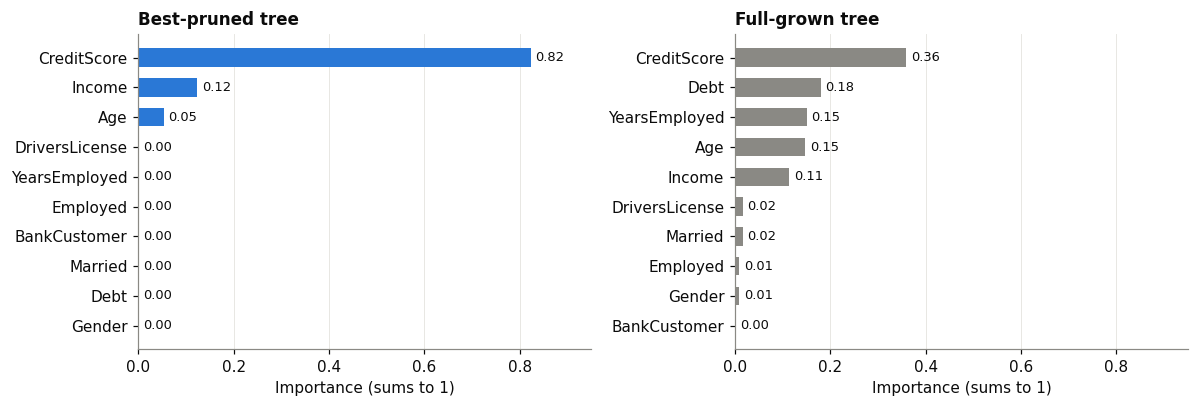


Protected characteristics with non-zero importance in the best-pruned tree: none


In [21]:
imp = pd.DataFrame({"Best-pruned tree": final_tree.feature_importances_,
                    "Full-grown tree": tree_full.feature_importances_}, index=X.columns)
print(imp.sort_values("Best-pruned tree", ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, col, color in zip(axes, imp.columns, [BLUE, GRAY]):
    s = imp[col].sort_values()
    ax.barh(s.index, s.values, color=color, height=0.62)
    for yv, v in enumerate(s.values):
        ax.text(v + 0.01, yv, f"{v:.2f}", va="center", fontsize=8.5)
    ax.set_title(col); ax.set_xlabel("Importance (sums to 1)"); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlim(0, 0.95)
plt.tight_layout(); plt.show()

print("\nProtected characteristics with non-zero importance in the best-pruned tree:",
      [c for c in ["Gender", "Married"] if imp.loc[c, "Best-pruned tree"] > 0] or "none")

🔍 **What to notice:**
- In the best-pruned tree, **`CreditScore` carries 82% of the importance**, followed by `Income` (12%) and `Age` (5%). The other 7 predictors have importance **0**: they were not needed.
- `Employed` has importance 0 even though it is strongly related to approval, because `CreditScore` carries exactly the same information (Step 1.3). **Zero importance means "not needed given the others", not "irrelevant".**
- The full-grown tree spreads importance over every predictor, `Debt` (18%), `YearsEmployed` (15%), `Age` (15%) and even `Gender` and `DriversLicense`, because it used them to chase noise.
- **Compliance check:** the best-pruned tree does **not** use `Gender` or `Married`, the characteristics the Equal Credit Opportunity Act protects. A fully grown tree can pick them up as accidental splits, which is one more reason to prune.

> ⚠️ **Watch out.** Importance depends on the tree. A different seed or a slightly different training sample can produce a different tree, and the ranking can change. Trees are **sensitive to small changes in the data**, one of the limitations from the video.

## Section 6 — From tree to business rules
📖 Every path from the root to a leaf is an **IF-THEN rule**. A tree with N leaves gives exactly N rules, and anyone can apply them **without a model object or any equations**.

### Step 6.1 — Print the tree as text
📖 `export_text` prints the tree with one line per node: each level of indentation is one more question, and the lines that end with a `class` are the leaves. `weights` is `[denied, approved]`.

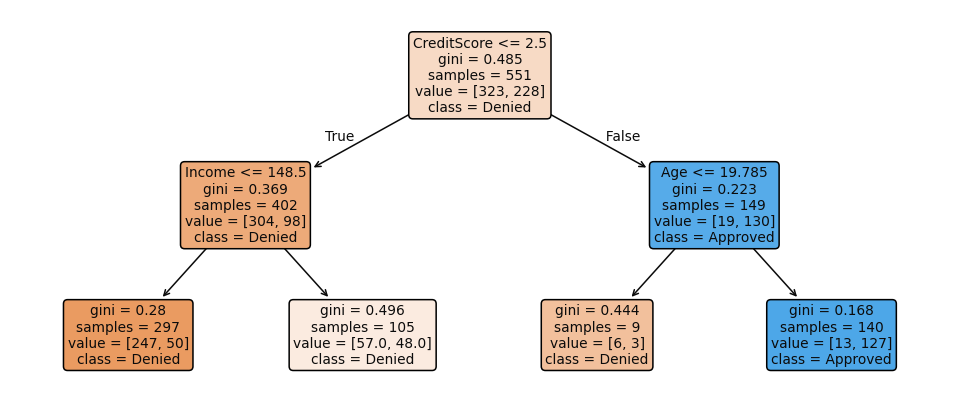

In [22]:
print(export_text(final_tree, feature_names=list(X.columns), show_weights=True))

|--- CreditScore <= 2.50
|   |--- Income <= 148.50
|   |   |--- weights: [247.00, 50.00] class: 0
|   |--- Income >  148.50
|   |   |--- weights: [57.00, 48.00] class: 0
|--- CreditScore >  2.50
|   |--- Age <= 19.78
|   |   |--- weights: [6.00, 3.00] class: 0
|   |--- Age >  19.78
|   |   |--- weights: [13.00, 127.00] class: 1



🔍 **What to notice:** read the text from the top: the first question is about `CreditScore`; each deeper level adds one more condition. This is the same tree as the picture in Step 4.4, just easier to copy into a report. The numbers after `weights` are how many training applicants of each class ended in that leaf.

### Step 6.2 — Extract every rule into a table
📖 We walk the tree from the root, collect the conditions along each path and record, for the leaf at the end of it, **how many applicants** it holds (support) and **what share of them was approved** (the probability of approval).

In [23]:
def extract_rules(model, feature_names):
    """One row per leaf: the IF-conditions on the path, support and approval probability."""
    t = model.tree_
    rows = []
    def walk(node, conds):
        if t.children_left[node] == -1:                                   # leaf
            v = t.value[node][0]; v = v / v.sum()                         # class shares (works for counts or proportions)
            n = int(t.n_node_samples[node])
            rows.append({"leaf": node, "n": n, "approved": int(round(v[1] * n)), "P(approved)": float(v[1]),
                         "conds": conds})
            return
        f, thr = feature_names[t.feature[node]], float(t.threshold[node])
        walk(t.children_left[node],  conds + [(f, "<=", thr)])
        walk(t.children_right[node], conds + [(f, ">",  thr)])
    walk(0, [])
    out = pd.DataFrame(rows).sort_values("P(approved)", ascending=False).reset_index(drop=True)
    out.insert(0, "Rule", out.index + 1)
    out["IF"]    = out["conds"].map(lambda cs: "  AND  ".join(f"{f} {op} {thr:.2f}" for f, op, thr in cs))
    out["query"] = out["conds"].map(lambda cs: " and ".join(f"{f} {op} {thr!r}" for f, op, thr in cs))
    out["THEN"]  = np.where(out["P(approved)"] >= 0.5, "APPROVE", "DENY")
    return out

rules = extract_rules(final_tree, list(X.columns))
pd.set_option("display.max_colwidth", None, "display.width", 200)
print(rules[["Rule", "IF", "THEN", "P(approved)", "n", "approved"]].round(3).to_string(index=False))

# Do the rules cover every training applicant exactly once?
print("\nApplicants covered by the rules:", int(rules["n"].sum()), "of", len(X_train))


 Rule                                         IF    THEN  P(approved)   n  approved
    1       CreditScore > 2.50  AND  Age > 19.78 APPROVE        0.907 140       127
    2  CreditScore <= 2.50  AND  Income > 148.50    DENY        0.457 105        48
    3      CreditScore > 2.50  AND  Age <= 19.78    DENY        0.333   9         3
    4 CreditScore <= 2.50  AND  Income <= 148.50    DENY        0.168 297        50

Applicants covered by the rules: 551 of 551


✅ **Expected result:** 4 rules (one per leaf), and together they cover all 551 training applicants exactly once.

🔍 **What to notice:**
- **Rule 1** is the most favorable: IF CreditScore > 2.50  AND  Age > 19.78 THEN approve; 127 of its 140 applicants (91%) were approved.
- **Rule 4** is the least favorable: IF CreditScore <= 2.50  AND  Income <= 148.50; only 17% of its 297 applicants were approved.
- **Rule 2** is a borderline case: 46% of its 105 applicants were approved. It lands on **DENY** only because it is below 50%. The tree gives a probability, and the threshold turns it into a decision.
- **Rule 3** (IF CreditScore > 2.50  AND  Age <= 19.78) holds only 9 applicants. Very small rules are fragile: before trusting one, ask whether it is a real pattern or an accident of a few cases.
- Because every applicant falls in exactly one rule, the rules are also a **segmentation** of the applicants. The cut-offs are the midpoints found by the split search of Step 3.2.
- **The cost of size:** a depth-4 tree needs 15 rules and the full-grown tree **96**. Nobody can read, explain or audit that many rules, which is another argument for the pruned tree.

### Step 6.3 — Test the Head of Retail Credit's belief
📖 The belief was: *"Income and low debt decide who is a good credit risk."* We compare the approval rate of the **high-income, low-debt** applicants (income in the top 25% and debt at or below the median) with everybody else, **inside each credit-score group**.

Income in the top 25% means Income >= 546; low debt means Debt <= 2.75

                                           approval rate  applicants
CreditScore <= 2.5 all others                      0.210         366
                   high income + low debt          0.583          36
CreditScore > 2.5  all others                      0.832          95
                   high income + low debt          0.944          54

Overall: high income + low debt = 80.0% approved | all others = 33.8%


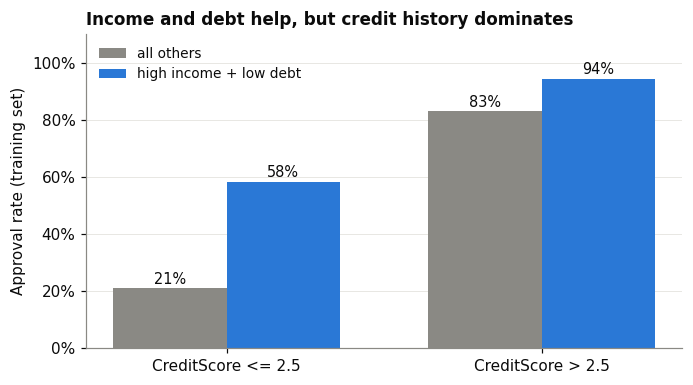

In [24]:
tr = X_train.assign(Approved=y_train)
high_inc_low_debt = (tr["Income"] >= tr["Income"].quantile(0.75)) & (tr["Debt"] <= tr["Debt"].median())
score_group = np.where(tr["CreditScore"] > 2.5, "CreditScore > 2.5", "CreditScore <= 2.5")

belief = (tr.groupby([score_group, np.where(high_inc_low_debt, "high income + low debt", "all others")])["Approved"]
            .agg(["mean", "size"]).rename(columns={"mean": "approval rate", "size": "applicants"}))
print(f"Income in the top 25% means Income >= {tr['Income'].quantile(0.75):.0f}; low debt means Debt <= {tr['Debt'].median():.2f}\n")
print(belief.round(3).to_string())
print(f"\nOverall: high income + low debt = {tr.loc[high_inc_low_debt, 'Approved'].mean():.1%} approved | all others = {tr.loc[~high_inc_low_debt, 'Approved'].mean():.1%}")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
groups = ["CreditScore <= 2.5", "CreditScore > 2.5"]
w = 0.36
for i, (lab, col) in enumerate([("all others", GRAY), ("high income + low debt", BLUE)]):
    vals = [belief.loc[(g, lab), "approval rate"] for g in groups]
    bars = ax.bar(np.arange(2) + (i - 0.5) * w, vals, width=w, color=col, label=lab)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=9.5)
ax.set_xticks(range(2)); ax.set_xticklabels(groups); ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("Approval rate (training set)"); ax.set_title("Income and debt help, but credit history dominates")
ax.legend(frameon=False, loc="upper left", fontsize=9); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

🔍 **What to notice:** the belief is **partly right**.
- **Right:** high-income, low-debt applicants are approved far more often than the others (80% against 34%), and the advantage holds **inside both credit-score groups**: 58% vs 21% when the credit score is low, 94% vs 83% when it is high.
- **Incomplete:** an applicant with a **good credit score but ordinary income and debt** is approved **83%** of the time, which is more than the **58%** of high-income, low-debt applicants who have a low score. Credit history outweighs income and debt, which is exactly what the tree said by putting `CreditScore` at the root and giving it most of the importance. Income appears in the pruned tree; `Debt` does not, because once `CreditScore` and `Income` are known, debt adds little.
- **Recommendation for the Head of Retail Credit:** screen by credit history first, then use income to separate the borderline applicants.

> ⚠️ **Watch out.** This is an association in historical decisions, not proof that income *causes* approval. Past decisions also reflect what underwriters looked at when deciding.

## Section 7 — Predict new applicants
📖 The real test of a model: applicants it has never seen. We score 20 new applicants, explain every decision with its rule, and only then compare with what really happened.

### Step 7.1 — Load the 20 new applicants
📖 Twenty applicants arrived after the 689 past applications were collected. The file holds their characteristics **and** what the bank finally decided (`Approved`), but we put the decision aside and do not look at it until Step 7.3.

In [27]:
FILE_NEW = "Creditcard_appr_newclts.csv"

if not os.path.exists(FILE_NEW):
    if IN_COLAB:
        print("Select Creditcard_appr_newclts.csv from your computer...")
        files.upload()
    else:
        raise FileNotFoundError(f"Put {FILE_NEW} in the same folder as this notebook.")
assert os.path.exists(FILE_NEW), "Upload Creditcard_appr_newclts.csv (the file name must match exactly)."

new_raw = pd.read_csv(FILE_NEW)
assert len(new_raw) == 20 and set(PRED) <= set(new_raw.columns), "Upload Creditcard_appr_newclts.csv here (20 rows)."

actual_new = new_raw.set_index("Client_ID")["Approved"]          # set aside: do not look yet
new = new_raw.set_index("Client_ID")[PRED]                       # predictors only, same columns and order as training
print(new.shape, "| decision set aside |", int(new.isna().sum().sum()), "missing")
new.head(8)

(20, 10) | decision set aside | 0 missing


,Gender,Age,Debt,Married,BankCustomer,YearsEmployed,Employed,CreditScore,DriversLicense,Income
Client_ID,,,,,,,,,,
NC001,1,18.77,7.567,0,0,0.277,0,0,0,95
NC002,1,20.01,8.969,0,0,0.183,1,2,0,1
NC003,0,27.52,0.360,0,0,0.000,0,0,0,15820
NC004,1,18.35,0.787,1,1,0.125,0,0,0,81
NC005,1,36.04,0.721,1,1,1.019,0,0,0,0
NC006,1,23.89,2.180,1,1,1.261,1,3,1,18
NC007,1,34.35,14.694,1,1,5.442,1,2,1,515
NC008,1,34.44,1.732,1,1,1.231,0,0,1,0


✅ **Expected result:** 20 applicants and 10 predictor columns, no missing values. The predictors are in the same units as in the 689 past applications.

> ⚠️ **Watch out.** New applicants must have **exactly the same columns, in the same units**, as the data the tree was trained on. Here `new = new_raw[PRED]` guarantees the same names and order. A different column order or unit would silently give wrong decisions.

### Step 7.2 — Predict the probability and apply the decision rule
📖 Probability first, then the rule: **approve if P(approved) ≥ 0.5**. Because we have the rules, we also report **which rule** each applicant fell into: that is the explanation the bank can give for the decision.

In [30]:
p_new = pd.Series(final_tree.predict_proba(new)[:, 1], index=new.index, name="P(approved)")
rule_of_leaf = dict(zip(rules["leaf"], rules["Rule"]))
rule_new = pd.Series([rule_of_leaf[l] for l in final_tree.apply(new)], index=new.index, name="Rule")

pred_tbl = new[["Age", "Debt", "YearsEmployed", "CreditScore", "Income"]].copy()
pred_tbl["Rule"] = rule_new
pred_tbl["P(approved)"] = p_new
pred_tbl["Decision at 0.5"] = np.where(p_new >= THR, "APPROVE", "DENY")
pred_tbl = pred_tbl.sort_values(["P(approved)", "CreditScore"], ascending=False)
print(pred_tbl.round(3).to_string())
print(f"\nApproved at 0.5: {int((p_new >= THR).sum())} of 20")

print("\nDifferent probabilities among these 20 applicants:", [float(v) for v in sorted(p_new.round(3).unique())])

             Age    Debt  YearsEmployed  CreditScore  Income  Rule  P(approved) Decision at 0.5
Client_ID                                                                                      
NC010      71.51   1.947          0.000           13    4290     1        0.907         APPROVE
NC012      23.59   2.071          2.272           11     471     1        0.907         APPROVE
NC014      47.46   2.438          9.207            8       5     1        0.907         APPROVE
NC013      24.38   2.002          0.453            4     421     1        0.907         APPROVE
NC006      23.89   2.180          1.261            3      18     1        0.907         APPROVE
NC007      34.35  14.694          5.442            2     515     2        0.457            DENY
NC017      20.58   6.077          0.531            2     400     2        0.457            DENY
NC003      27.52   0.360          0.000            0   15820     2        0.457            DENY
NC016      31.97   0.491          1.173 

🔍 **What to notice:**
- The tree approves **5 of the 20** applicants. Probabilities range from **17%** to **91%**.
- Every decision comes with a reason. For example, **NC010** (approve, P = 91%) falls in Rule 1: *CreditScore > 2.50  AND  Age > 19.78*. **NC019** (deny, P = 17%) falls in Rule 4: *CreditScore <= 2.50  AND  Income <= 148.50*. This is the kind of explanation a lender can give an applicant.
- A 4-leaf tree can output only **4 different probabilities**, and these 20 applicants landed in just 3 of its rules (17%, 46%, 91%), so many applicants **tie**. A bigger tree gives finer probabilities, but, as Section 5 showed, at the price of overfitting. That is the trade-off between a readable model and a detailed one.

### Step 7.3 — Reveal what happened
📖 Now we open the decision we set aside and compare it with the tree's prediction, applicant by applicant.

In [31]:
compare = pred_tbl[["Rule", "P(approved)", "Decision at 0.5"]].copy()
compare["Actual"] = np.where(actual_new.reindex(compare.index) == 1, "APPROVE", "DENY")
compare["Correct?"] = np.where(compare["Decision at 0.5"] == compare["Actual"], "yes", "NO")
print(compare.round(3).to_string())

pred_new = (p_new >= THR).astype(int)
cm_new = confusion_matrix(actual_new.reindex(p_new.index), pred_new)
m_new = metrics_at(actual_new.reindex(p_new.index), p_new, THR)
print(f"\nAccuracy on the 20 new applicants: {m_new['Accuracy']:.2f}  (baseline 'deny everybody': {1 - actual_new.mean():.2f})")
print(pd.DataFrame(cm_new, index=["Actual denied", "Actual approved"], columns=["Predicted denied", "Predicted approved"]).to_string())
print("Mistakes:", list(compare.index[compare["Correct?"] == "NO"]))

           Rule  P(approved) Decision at 0.5   Actual Correct?
Client_ID                                                     
NC010         1        0.907         APPROVE  APPROVE      yes
NC012         1        0.907         APPROVE  APPROVE      yes
NC014         1        0.907         APPROVE  APPROVE      yes
NC013         1        0.907         APPROVE  APPROVE      yes
NC006         1        0.907         APPROVE     DENY       NO
NC007         2        0.457            DENY  APPROVE       NO
NC017         2        0.457            DENY  APPROVE       NO
NC003         2        0.457            DENY  APPROVE       NO
NC016         2        0.457            DENY     DENY      yes
NC018         2        0.457            DENY     DENY      yes
NC020         2        0.457            DENY  APPROVE       NO
NC002         4        0.168            DENY     DENY      yes
NC001         4        0.168            DENY     DENY      yes
NC004         4        0.168            DENY     DENY  

🔍 **What to notice:** the tree decided **15 of the 20** applicants correctly (accuracy **0.75**), against a baseline of 0.60 for "deny everybody". It made **1 risky approval** (NC006) and **missed 4 good applicants** (NC007, NC017, NC003, NC020).
- **4 of the 5 mistakes fall in Rule 2**, the 46% rule: 6 of the 20 applicants landed there and the tree can only say "a bit less than half of applicants like this are approved". When a rule sits close to 50%, the decision is almost a coin toss, and that is where the tree is least reliable.
- Every mistake can be traced to its rule, so the bank knows *which* part of the tree to question. We should **not** move the threshold just to fit these 20 applicants: a threshold has to be justified with the cost of each error on a large sample, as in Week 4.

> ⚠️ **Watch out.** Twenty applicants is a very small sample: one more or less correct decision moves accuracy by 5 points. Use this step to **see the model at work**, and trust the cross-validation and the 138-applicant test set, not these 20, for the quality of the model.

## Quick reference and practice

### Recipes you can reuse
| Goal | Code recipe |
|---|---|
| 80/20 split with seed | `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)` |
| Gini of a node | `1 - sum(p**2)` with `p = counts / counts.sum()` (Step 3.1) |
| Fit a tree | `DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)` |
| Draw the tree | `plot_tree(tree, feature_names=list(X.columns), class_names=[...], filled=True)` |
| Print the tree as text | `export_text(tree, feature_names=list(X.columns), show_weights=True)` |
| Size and leaves | `tree.get_depth()`, `tree.get_n_leaves()` |
| Folds | `StratifiedKFold(n_splits=10, shuffle=True, random_state=42)` |
| Cross-validated scores | `cross_validate(tree, X_train, y_train, cv=skf, scoring=["accuracy", "roc_auc"], return_train_score=True)` |
| Search the depth in one call | `GridSearchCV(DecisionTreeClassifier(random_state=42), {"max_depth": range(1, 13)}, cv=skf, scoring="roc_auc").fit(X_train, y_train)` |
| Minimum-error / best-pruned depth | `idxmax()` of the CV score; smallest depth with CV score ≥ best − 1 SE (Step 4.3) |
| Probability and decision | `tree.predict_proba(X)[:, 1]`, then `>= 0.5` |
| Confusion matrix, metrics | `confusion_matrix(y, pred)`, `metrics_at(y, p, thr)` (Step 5.1) |
| ROC and AUC | `roc_curve(y, p)`, `roc_auc_score(y, p)` |
| Variable importance | `tree.feature_importances_` |
| Rules as a table | `extract_rules(tree, list(X.columns))` (Step 6.2) |
| Apply rules without the model | `apply_rules(new_df, rules)` (Step 6.3) |
| Which rule does a case fall in? | `tree.apply(new_df)` gives the leaf; map it to its rule |

### Practice
Try these on your own before opening the solution cell.
1. What is the Gini index of a node with 30 approved and 10 denied applicants?
2. What are the 10-fold cross-validated **AUC** and **accuracy** of a tree with `max_depth=3` (use the same folds `skf`)?
3. Use `GridSearchCV` with `scoring="roc_auc"` over depths 1 to 12. Which depth does it pick, and how does it compare with the best-pruned depth of Step 4.3?
4. Fit a tree with `min_samples_leaf=20` and **no** `max_depth`. How many leaves does it have, and what is its test AUC? Why should you **not** decide between this tree and the best-pruned tree by comparing their test AUC?
5. Extract the rules of the depth-3 tree. How many of its rules say APPROVE?

In [32]:
# ---- Solutions ----
# 1. Gini of 30 approved / 10 denied
print(f"1. Gini = {gini([10, 30]):.3f}")

# 2. CV of a depth-3 tree
r3 = cross_validate(DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, y_train, cv=skf, scoring=["accuracy", "roc_auc"])
print(f"2. CV AUC = {r3['test_roc_auc'].mean():.3f} | CV accuracy = {r3['test_accuracy'].mean():.3f}")

# 3. GridSearchCV
gs = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {"max_depth": list(range(1, 13))}, cv=skf, scoring="roc_auc").fit(X_train, y_train)
print(f"3. GridSearchCV picks depth {gs.best_params_['max_depth']} (best CV AUC {gs.best_score_:.3f}); best-pruned depth from Step 4.3 = {pruned_depth}")

# 4. Control size with min_samples_leaf
t20 = DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED).fit(X_train, y_train)
print(f"4. leaves = {t20.get_n_leaves()} | depth = {t20.get_depth()} | test AUC = {roc_auc_score(y_test, t20.predict_proba(X_test)[:, 1]):.3f}")
print("   Limiting leaf size is another valid way to control complexity. But a choice made by looking at the test AUC uses the test set to select,")
print("   so the score is no longer an honest estimate. To choose min_samples_leaf, cross-validate it on the training set (GridSearchCV), as in Step 4.3.")

# 5. Rules of the depth-3 tree
r_d3 = extract_rules(tree3, list(X.columns))
print(f"5. {len(r_d3)} rules, of which {int((r_d3['THEN'] == 'APPROVE').sum())} say APPROVE")

1. Gini = 0.375
2. CV AUC = 0.800 | CV accuracy = 0.777
3. GridSearchCV picks depth 4 (best CV AUC 0.804); best-pruned depth from Step 4.3 = 2
4. leaves = 19 | depth = 7 | test AUC = 0.846
   Limiting leaf size is another valid way to control complexity. But a choice made by looking at the test AUC uses the test set to select,
   so the score is no longer an honest estimate. To choose min_samples_leaf, cross-validate it on the training set (GridSearchCV), as in Step 4.3.
5. 8 rules, of which 4 say APPROVE


## Wrap-up — Key ideas
- **CART** builds a tree by recursively splitting the data on the predictor and cut-off that most reduce the **Gini index** of the resulting groups. Gini is 0 for a pure node and 0.5 for an even mix of two classes. In this lab the first split was `CreditScore ≤ 2.5`.
- Read a node by its question, `samples`, `value` (class counts), `gini` and class. **Every path from the root to a leaf is an IF-THEN rule**, and N leaves give N rules.
- Trees need **no standardizing**: they only compare values with a cut-off, and rescaling does not change the order of the values.
- A **full-grown tree overfits**: 96 leaves, perfect training accuracy, but a cross-validated accuracy of only 0.74 and a test AUC of 0.70.
- **k-fold cross-validation** estimates new-data performance from the training set alone: every applicant is validated once, and the average of the k scores (with its standard error) replaces a single, lucky-or-unlucky split. The test set stays untouched until the end.
- The **minimum-error tree** (best CV score, depth 4) and the **best-pruned tree** (simplest tree within one standard error, depth 2) are the two classic choices. We used the best-pruned tree: 4 leaves, test AUC 0.79.
- **Variable importance** ranks predictors by the Gini they remove. A predictor with zero importance can still be informative if another predictor carries the same information (`Employed` and `CreditScore`). The pruned tree did not use `Gender` or `Married`.
- The belief that income and low debt decide was **partly right**: they help inside every credit-score group, but credit history carries more weight.
- A tree is easy to explain, handles mixed data and needs little preparation, but it is **sensitive to small changes in the data**, needs a sizeable training set and overfits unless it is pruned. Reach for it when decisions must be **transparent**.
- To **predict new applicants**, give them the same columns and units as the training data, predict a probability, apply the threshold, and report the rule behind each decision.

*End of the Week 5 lab.*